- From all possible parameter configurations try PCA
- Use Elisa's paper to try different n values for different neuron types
- Sparsity test on the two subsets of eigenvectors
- Plot y_average for a range of inputs x=0 to 2

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax


# set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

In [2]:
# find mitral output using solved g
# currently without granule cell
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)

    base_y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)

    return r, g, b, base_y  # Return base_y as y (granule cell computation is commented out)


# solve fixed point via Anderson - return g
# Use the local mitral_fixed_point function
def solve_fixed_point(theta, x, m):
    # Unpack all parameters needed for mitral_fixed_point
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Local mitral_fixed_point signature: (g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    g_fixed = solution.params
    return g_fixed

# fixed-point function
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """
    Fixed point equation for green neurons
    """
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)

    return g_new


# unpack parameter
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m  # Matrix: cross-channel connections g->r
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m  # Matrix: cross-channel connections g->y (was W_g_m)
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)


In [3]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [4]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 982 out of 1000


In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA



theta_pca = StandardScaler().fit_transform(theta_opt)  # mean-center + scale

pca = PCA(n_components=theta_opt.shape[1])
pca.fit(theta_pca)

PCs = pca.components_      # shape (28, 28)
explained_var = pca.explained_variance_ 

In [12]:
print(pca.components_[0])
print(PCs.shape)
print(explained_var)

[-2.70232588e-01  1.83478743e-01  3.11405480e-01 -2.58740336e-01
  4.00833450e-02 -2.67895237e-02 -1.09749585e-01  1.04351319e-01
  3.28332692e-01 -2.39408016e-01 -4.66167182e-03  1.47899818e-02
  2.31368870e-01 -1.57327831e-01 -1.71313092e-01  1.20756909e-01
  8.64661783e-02 -7.75904804e-02 -2.97539622e-01  2.50793606e-01
 -1.38615680e-26  3.41863036e-01 -2.50764638e-01  1.54679619e-27
  0.00000000e+00  2.18755633e-01 -1.55007139e-01  0.00000000e+00]
(28, 28)
[3.7483618e+00 3.0027363e+00 2.1343195e+00 1.8950067e+00 1.7390860e+00
 1.6323317e+00 1.2701999e+00 1.2349533e+00 1.0811555e+00 1.0480291e+00
 9.1140288e-01 8.9831114e-01 5.4459673e-01 4.8871338e-01 4.8043916e-01
 4.2682993e-01 3.7864557e-01 3.4881461e-01 2.1600886e-01 1.9516635e-01
 1.5795353e-01 1.5541656e-01 1.9771999e-02 1.6213613e-02 5.4952880e-17
 6.5515819e-18 0.0000000e+00 0.0000000e+00]


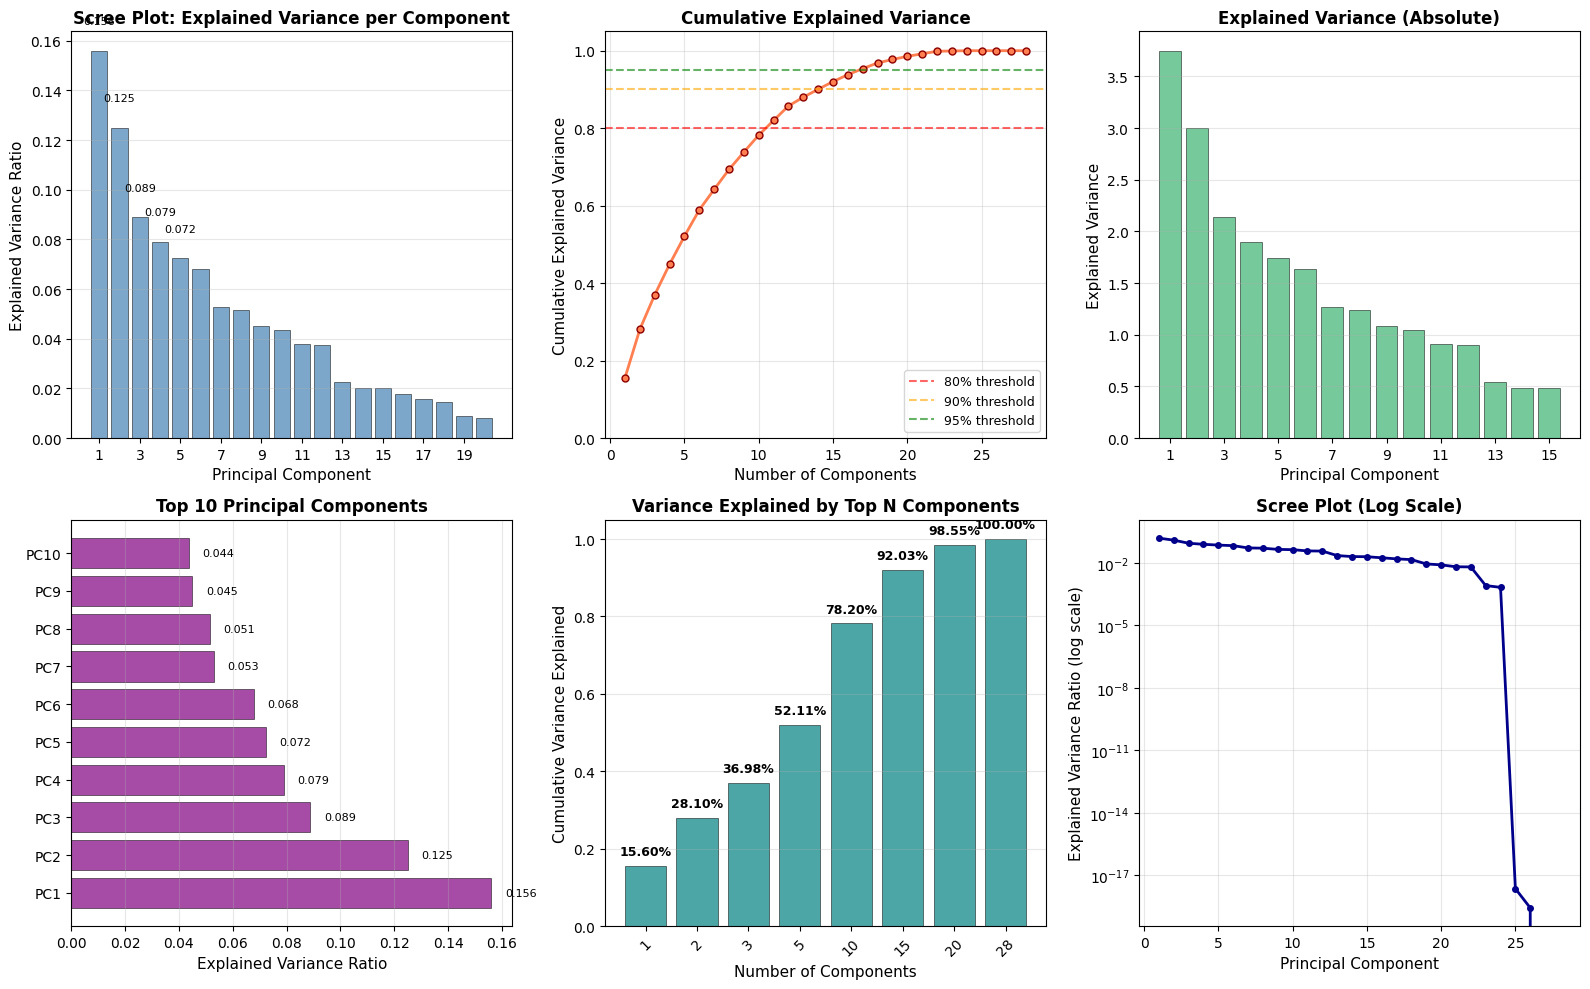

PCA COMPONENT SIGNIFICANCE SUMMARY

Total number of components: 28

Top 5 Components Explained Variance:
  PC1: 0.1560 (15.60%)
  PC2: 0.1250 (12.50%)
  PC3: 0.0888 (8.88%)
  PC4: 0.0789 (7.89%)
  PC5: 0.0724 (7.24%)

Cumulative Variance Explained:
  Top  1 components: 0.1560 (15.60%)
  Top  2 components: 0.2810 (28.10%)
  Top  3 components: 0.3698 (36.98%)
  Top  5 components: 0.5211 (52.11%)
  Top 10 components: 0.7820 (78.20%)
  Top 15 components: 0.9203 (92.03%)
  Top 20 components: 0.9855 (98.55%)

Components needed for variance thresholds:
  80% variance: 11 components
  90% variance: 14 components
  95% variance: 17 components
  99% variance: 21 components


In [11]:
# Calculate explained variance ratio and cumulative variance
explained_var_ratio = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var_ratio)

# Create comprehensive plots to show PCA component significance
fig = plt.figure(figsize=(16, 10))

# Plot 1: Scree plot - Explained variance ratio per component
ax1 = plt.subplot(2, 3, 1)
n_components_show = min(20, len(explained_var_ratio))
bars = ax1.bar(range(1, n_components_show + 1), 
               explained_var_ratio[:n_components_show], 
               alpha=0.7, color='steelblue', edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Principal Component', fontsize=11)
ax1.set_ylabel('Explained Variance Ratio', fontsize=11)
ax1.set_title('Scree Plot: Explained Variance per Component', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_xticks(range(1, n_components_show + 1, 2))

# Add value labels on top of bars for top 5 components
for i in range(min(5, n_components_show)):
    height = explained_var_ratio[i]
    ax1.text(i + 1, height + 0.01, f'{height:.3f}', 
             ha='center', va='bottom', fontsize=8)

# Plot 2: Cumulative explained variance
ax2 = plt.subplot(2, 3, 2)
ax2.plot(range(1, len(cumulative_var) + 1), cumulative_var, 
         marker='o', linewidth=2, markersize=5, color='coral', markeredgecolor='darkred')
ax2.axhline(y=0.8, color='r', linestyle='--', alpha=0.6, linewidth=1.5, label='80% threshold')
ax2.axhline(y=0.9, color='orange', linestyle='--', alpha=0.6, linewidth=1.5, label='90% threshold')
ax2.axhline(y=0.95, color='g', linestyle='--', alpha=0.6, linewidth=1.5, label='95% threshold')
ax2.set_xlabel('Number of Components', fontsize=11)
ax2.set_ylabel('Cumulative Explained Variance', fontsize=11)
ax2.set_title('Cumulative Explained Variance', fontsize=12, fontweight='bold')
ax2.legend(loc='lower right', fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.set_ylim([0, 1.05])

# Plot 3: Explained variance (not ratio) - shows absolute variance
ax3 = plt.subplot(2, 3, 3)
n_components_show = min(15, len(explained_var))
ax3.bar(range(1, n_components_show + 1), 
        explained_var[:n_components_show], 
        alpha=0.7, color='mediumseagreen', edgecolor='black', linewidth=0.5)
ax3.set_xlabel('Principal Component', fontsize=11)
ax3.set_ylabel('Explained Variance', fontsize=11)
ax3.set_title('Explained Variance (Absolute)', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')
ax3.set_xticks(range(1, n_components_show + 1, 2))

# Plot 4: Top 10 components comparison
ax4 = plt.subplot(2, 3, 4)
top_n = min(10, len(explained_var_ratio))
x_pos = np.arange(1, top_n + 1)
bars = ax4.barh(x_pos, explained_var_ratio[:top_n], 
                alpha=0.7, color='purple', edgecolor='black', linewidth=0.5)
ax4.set_yticks(x_pos)
ax4.set_yticklabels([f'PC{i}' for i in range(1, top_n + 1)])
ax4.set_xlabel('Explained Variance Ratio', fontsize=11)
ax4.set_title('Top 10 Principal Components', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='x')
# Add value labels
for i, (bar, val) in enumerate(zip(bars, explained_var_ratio[:top_n])):
    ax4.text(val + 0.005, i + 1, f'{val:.3f}', 
             va='center', fontsize=8)

# Plot 5: Variance explained by top N components
ax5 = plt.subplot(2, 3, 5)
n_values = [1, 2, 3, 5, 10, 15, 20, len(explained_var_ratio)]
var_explained = [cumulative_var[n-1] for n in n_values if n <= len(cumulative_var)]
n_values = [n for n in n_values if n <= len(cumulative_var)]
bars = ax5.bar(range(len(n_values)), var_explained, 
               alpha=0.7, color='teal', edgecolor='black', linewidth=0.5)
ax5.set_xticks(range(len(n_values)))
ax5.set_xticklabels([f'{n}' for n in n_values], rotation=45)
ax5.set_xlabel('Number of Components', fontsize=11)
ax5.set_ylabel('Cumulative Variance Explained', fontsize=11)
ax5.set_title('Variance Explained by Top N Components', fontsize=12, fontweight='bold')
ax5.grid(True, alpha=0.3, axis='y')
# Add value labels
for i, (bar, val) in enumerate(zip(bars, var_explained)):
    ax5.text(i, val + 0.02, f'{val:.2%}', 
             ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 6: Log scale scree plot to see all components
ax6 = plt.subplot(2, 3, 6)
ax6.semilogy(range(1, len(explained_var_ratio) + 1), explained_var_ratio, 
             marker='o', linewidth=2, markersize=4, color='darkblue')
ax6.set_xlabel('Principal Component', fontsize=11)
ax6.set_ylabel('Explained Variance Ratio (log scale)', fontsize=11)
ax6.set_title('Scree Plot (Log Scale)', fontsize=12, fontweight='bold')
ax6.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

# Print summary statistics
print("=" * 70)
print("PCA COMPONENT SIGNIFICANCE SUMMARY")
print("=" * 70)
print(f"\nTotal number of components: {len(explained_var_ratio)}")
print(f"\nTop 5 Components Explained Variance:")
for i in range(min(5, len(explained_var_ratio))):
    print(f"  PC{i+1}: {explained_var_ratio[i]:.4f} ({explained_var_ratio[i]*100:.2f}%)")

print(f"\nCumulative Variance Explained:")
for n in [1, 2, 3, 5, 10, 15, 20]:
    if n <= len(cumulative_var):
        print(f"  Top {n:2d} components: {cumulative_var[n-1]:.4f} ({cumulative_var[n-1]*100:.2f}%)")

# Find number of components for different thresholds
print(f"\nComponents needed for variance thresholds:")
for threshold in [0.8, 0.9, 0.95, 0.99]:
    n_components = np.argmax(cumulative_var >= threshold) + 1
    if n_components <= len(cumulative_var):
        print(f"  {threshold*100:.0f}% variance: {n_components} components")
    else:
        print(f"  {threshold*100:.0f}% variance: Not achievable with available components")
print("=" * 70)


## n values